In [56]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

In [57]:
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=4, 
    n_redundant=6,
    n_repeated=0,
    n_classes=2,
    random_state=42
)

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.62      0.74      0.67        91
           1       0.74      0.62      0.68       109

    accuracy                           0.68       200
   macro avg       0.68      0.68      0.67       200
weighted avg       0.69      0.68      0.68       200



In [59]:
probablities = model.predict_proba(X_test)[:, 1]
(probablities > 0.4).astype(int)

array([0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 0])

In [60]:
probablities = model.predict_proba(X_test)[:, 1]
y_pred = (probablities > 0.4).astype(int)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.60      0.53      0.56        91
           1       0.64      0.71      0.67       109

    accuracy                           0.62       200
   macro avg       0.62      0.62      0.62       200
weighted avg       0.62      0.62      0.62       200



In [61]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, probablities)
fpr[:5], tpr[:5], thresholds[:5]

(array([0.        , 0.        , 0.        , 0.01098901, 0.01098901]),
 array([0.        , 0.00917431, 0.1559633 , 0.1559633 , 0.16513761]),
 array([       inf, 0.96930077, 0.85917858, 0.85538256, 0.85481921]))

In [62]:
tpr

array([0.        , 0.00917431, 0.1559633 , 0.1559633 , 0.16513761,
       0.16513761, 0.25688073, 0.25688073, 0.32110092, 0.32110092,
       0.34862385, 0.34862385, 0.35779817, 0.35779817, 0.43119266,
       0.43119266, 0.44954128, 0.44954128, 0.46788991, 0.46788991,
       0.50458716, 0.50458716, 0.52293578, 0.52293578, 0.55963303,
       0.55963303, 0.57798165, 0.57798165, 0.59633028, 0.59633028,
       0.60550459, 0.60550459, 0.63302752, 0.63302752, 0.65137615,
       0.65137615, 0.66055046, 0.66055046, 0.67889908, 0.67889908,
       0.68807339, 0.68807339, 0.69724771, 0.69724771, 0.70642202,
       0.70642202, 0.71559633, 0.71559633, 0.73394495, 0.73394495,
       0.74311927, 0.74311927, 0.7706422 , 0.7706422 , 0.79816514,
       0.79816514, 0.81651376, 0.81651376, 0.82568807, 0.82568807,
       0.86238532, 0.86238532, 0.87155963, 0.87155963, 0.88073394,
       0.88073394, 0.88990826, 0.88990826, 0.89908257, 0.89908257,
       0.91743119, 0.91743119, 0.9266055 , 0.9266055 , 0.93577

In [67]:
desired_recall = 0.9

closest_index = np.argmin(abs(tpr - desired_recall))
closest_index

np.int64(68)

In [68]:
thresholds[closest_index], fpr[closest_index]

(np.float64(0.2615182575795018), np.float64(0.6593406593406593))

In [69]:
from sklearn.metrics import auc

area = auc(fpr, tpr)
area

0.7372719024095172

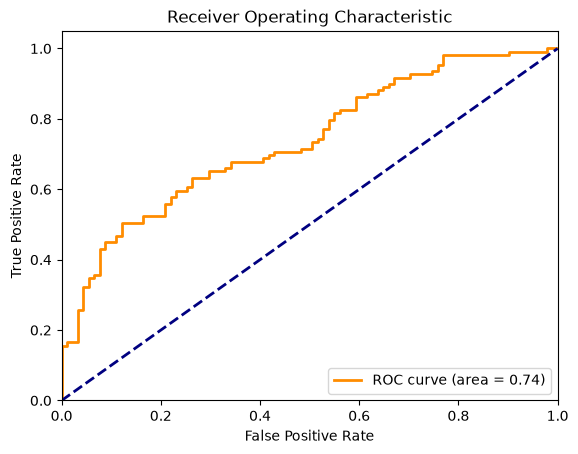

In [70]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [71]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

model = XGBClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.88      0.92      0.90        91
           1       0.93      0.89      0.91       109

    accuracy                           0.91       200
   macro avg       0.90      0.91      0.90       200
weighted avg       0.91      0.91      0.91       200



In [ ]:
y_scores = model.predict_proba(X_test)[:, 1]
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, y_scores)
area2 = auc(fpr_xgb, tpr_xgb)
area2

0.9599758040125013

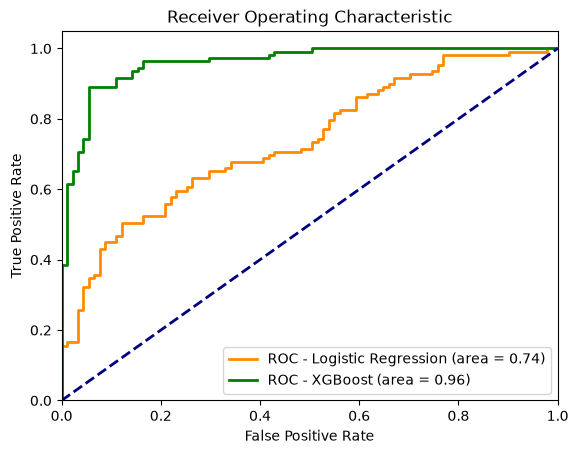

In [74]:
plt.figure()

plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC - Logistic Regression (area = %0.2f)' % area)
plt.plot(fpr_xgb, tpr_xgb, color='green', lw=2, label='ROC - XGBoost (area = %0.2f)' % area2)

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [79]:
desired_recall = 0.92

closest_index = np.argmin(abs(tpr_xgb-desired_recall))
tpr_xgb[closest_index], thresholds_xgb[closest_index], fpr_xgb[closest_index]

(np.float64(0.9174311926605505),
 np.float64(0.34150347113609314),
 np.float64(0.10989010989010989))

In [80]:
thresholds_xgb[closest_index], fpr_xgb[closest_index]

(np.float64(0.34150347113609314), np.float64(0.10989010989010989))